In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_json("streaming_music.json")

display(df.head())
print(df.columns)

,track_id,track_name,genre,minutes,popularity,release_year,streams_millions,city,latitude,longitude
0,1,Track 001,Pop,3.04,65,2023,54.3,New York,40.7128,-74.0060
1,2,Track 002,Hip-hop,4.98,83,2014,56.7,Chicago,41.8781,-87.6298
2,3,Track 003,Rock,3.32,86,2024,201.6,Miami,25.7617,-80.1918
3,4,Track 004,Electronic,4.00,68,2012,151.7,Miami,25.7617,-80.1918
4,5,Track 005,Jazz,6.22,63,2022,124.6,Seattle,47.6062,-122.3321


Index(['track_id', 'track_name', 'genre', 'minutes', 'popularity',
       'release_year', 'streams_millions', 'city', 'latitude', 'longitude'],
      dtype='str')


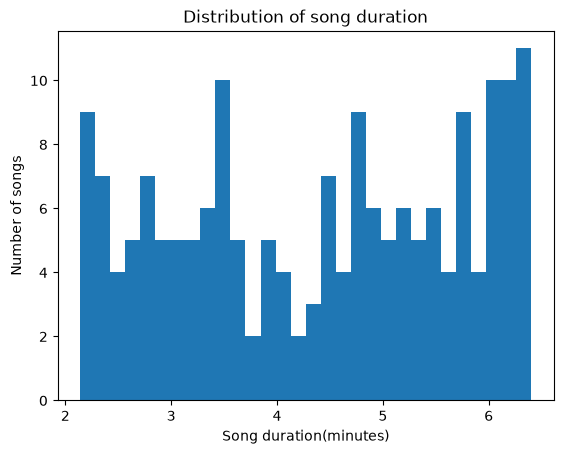

In [5]:
plt.hist(df["minutes"], bins=30)
plt.title("Distribution of song duration")
plt.xlabel("Song duration(minutes)")
plt.ylabel("Number of songs")
plt.show()

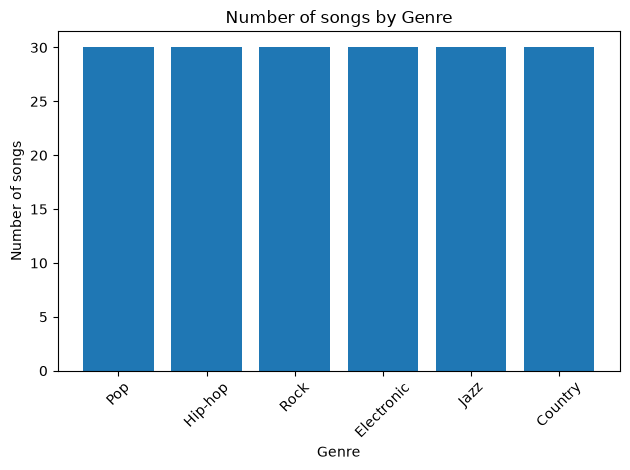

In [8]:
genre_counts = df["genre"].value_counts()

plt.bar( 
    genre_counts.index,
    genre_counts.values
)

plt.title("Number of songs by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of songs")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

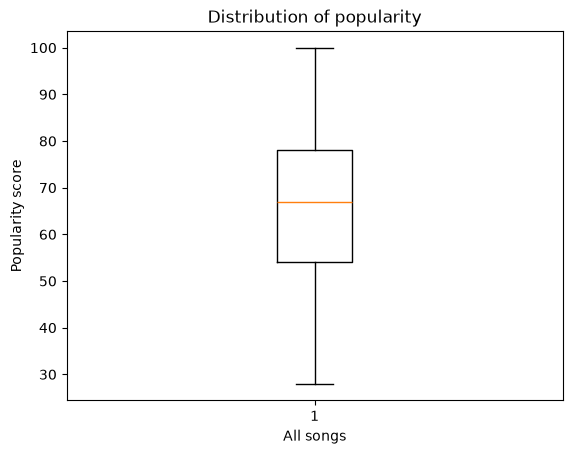

In [10]:
plt.boxplot(df["popularity"])
plt.title("Distribution of popularity")
plt.xlabel("All songs")
plt.ylabel("Popularity score")
plt.show()

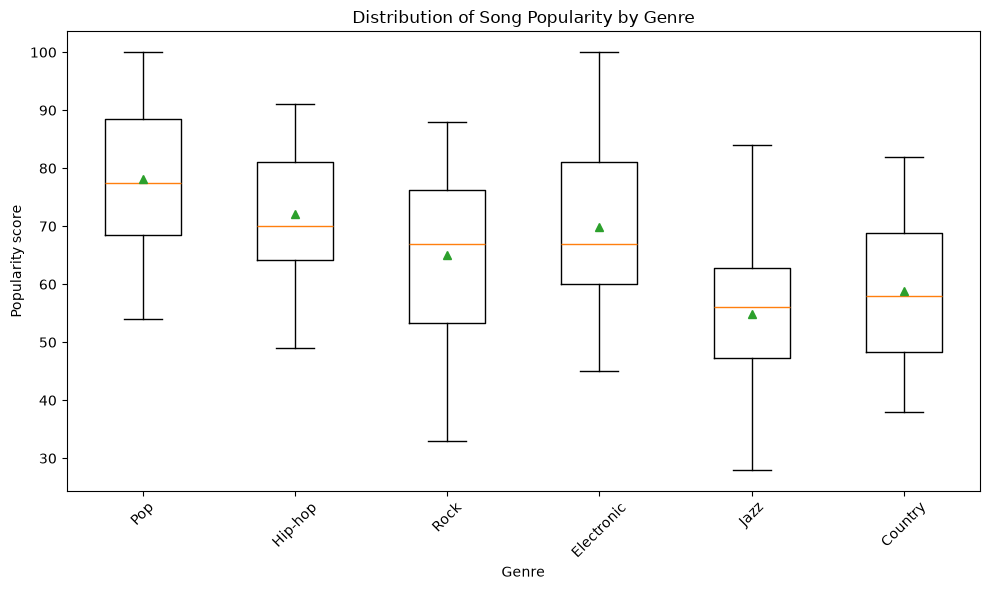

In [20]:
genres = df["genre"].unique()

popularity_genre = [
    df.loc[df["genre"] == genre, "popularity"]
    for genre in genres
]

plt.figure(figsize=(10, 6))
plt.boxplot(popularity_genre, tick_labels=genres, showmeans=True)

plt.title("Distribution of Song Popularity by Genre")
plt.xlabel("Genre")
plt.ylabel("Popularity score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

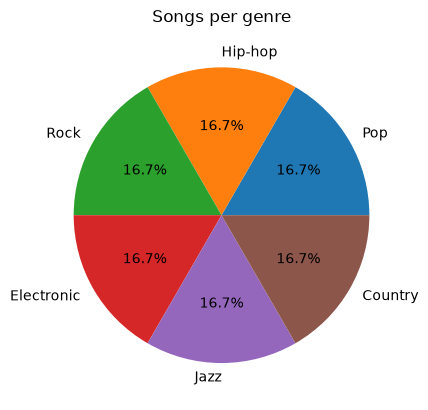

In [15]:
genre_counts = df["genre"].value_counts()

plt.pie(
    genre_counts.values,
    labels=genre_counts.index,
    autopct = "%1.1f%%
)
plt.title("Songs per genre")
plt.show()

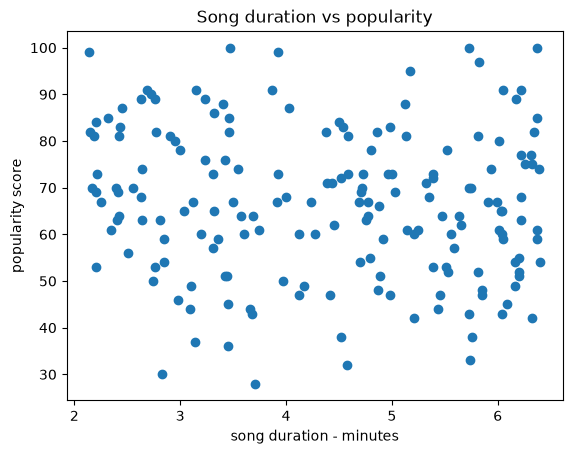

In [17]:
plt.scatter(
    df["minutes"],
    df["popularity"]
)

plt.title("Song duration vs popularity")
plt.xlabel("song duration - minutes")
plt.ylabel("popularity score")
plt.show()

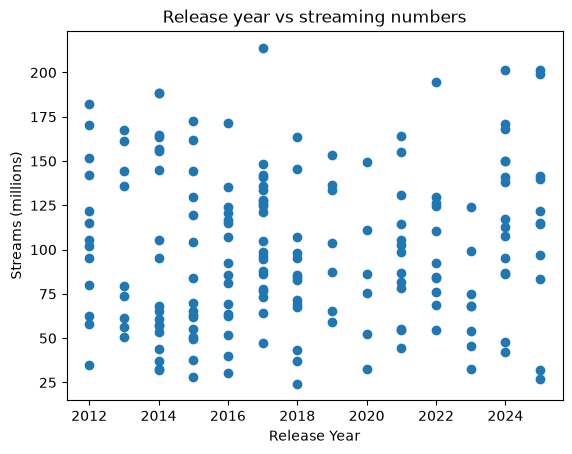

In [18]:
plt.scatter(
    df["release_year"],
    df["streams_millions"]
)
plt.title("Release year vs streaming numbers")
plt.xlabel("Release Year")
plt.ylabel("Streams (millions)")
plt.show()

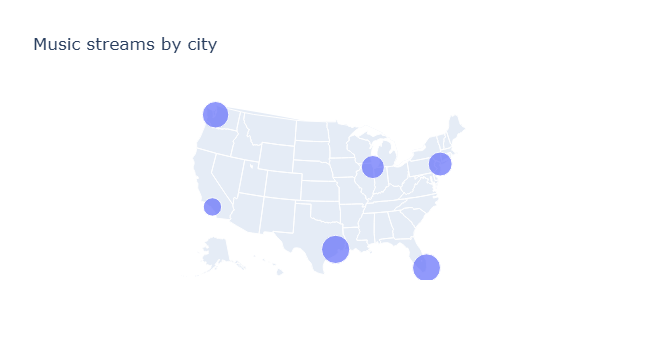

In [21]:
import plotly.express as px

city_streams = df.groupby(
    ["city", "latitude", "longitude"],
    as_index=False
)["streams_millions"].sum()

fig = px.scatter_geo(
    city_streams, 
    lat="latitude",
    lon="longitude",
    size="streams_millions",
    hover_name="city",
    scope="usa",
    title="Music streams by city"
)
fig.show()

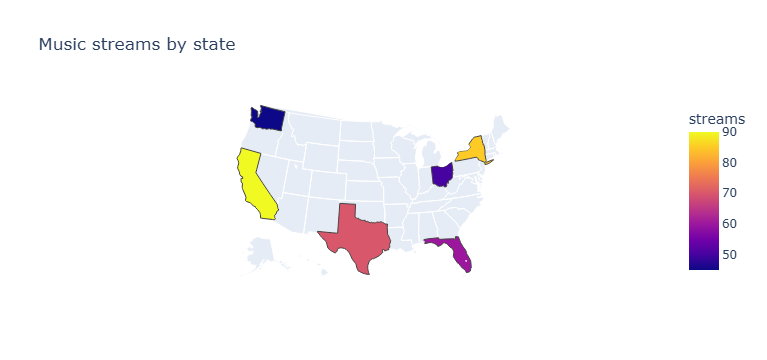

In [22]:
states = pd.DataFrame({
    "state":["OH","CA","NY","TX","FL","WA"],
    "streams":[50,90,85,70,60,45]
})

fig = px.choropleth(
    states,
    locations="state",
    locationmode="USA-states",
    color="streams",
    scope="usa",
    title="Music streams by state"
)
fig.show()